In [1]:
!pip -q install openpyxl

import pandas as pd

df = pd.read_excel(
    "/content/Muskoka_Area_Intensive_Sentinel lakes_Temperature_and_dissolved_oxygen_1976-2021- Revised and Raw Data.xlsx",
    engine="openpyxl"
)

display(df.head())


,LAKE,DISTRICT,TOWNSHIP,LATITUDE,LONGITUDE,DATE,YEAR,MONTH,SEASON,DEPTH,TEMPERATURE,DISSOLVED OXYGEN,STATION
0,BLUE CHALK LAKE,Muskoka Dist.,Ridout,451156,785631,1976-02-18,1976,2,Winter,0.1,0.90,NaN,3007754001
1,BLUE CHALK LAKE,Muskoka Dist.,Ridout,451156,785631,1976-02-18,1976,2,Winter,1.0,2.40,NaN,3007754001
2,BLUE CHALK LAKE,Muskoka Dist.,Ridout,451156,785631,1976-02-18,1976,2,Winter,2.0,3.00,NaN,3007754001
3,BLUE CHALK LAKE,Muskoka Dist.,Ridout,451156,785631,1976-02-18,1976,2,Winter,3.0,3.75,NaN,3007754001
4,BLUE CHALK LAKE,Muskoka Dist.,Ridout,451156,785631,1976-02-18,1976,2,Winter,4.0,3.80,NaN,3007754001


In [2]:
df.shape

(104319, 13)

In [3]:
df.isnull().sum()



,0
LAKE,0
DISTRICT,0
TOWNSHIP,0
LATITUDE,0
LONGITUDE,0
DATE,0
YEAR,0
MONTH,0
SEASON,0
DEPTH,0


In [4]:
blank_percentage = (df.isnull().sum() / len(df)) * 100

print('Percent of missing variables:',blank_percentage.round(2))


Percent of missing variables: LAKE                 0.00
DISTRICT             0.00
TOWNSHIP             0.00
LATITUDE             0.00
LONGITUDE            0.00
DATE                 0.00
YEAR                 0.00
MONTH                0.00
SEASON               0.00
DEPTH                0.00
TEMPERATURE          2.77
DISSOLVED OXYGEN    25.65
STATION              0.00
dtype: float64


In [5]:
for lake in df['LAKE'].unique():
    lake_data = df[df['LAKE'] == lake]
    missing_percent = lake_data['DISSOLVED OXYGEN'].isna().mean() * 100
    print(lake, round(missing_percent, 2), "%")

BLUE CHALK LAKE 29.15 %
CHUB LAKE 27.07 %
CROSSON LAKE 27.89 %
DICKIE LAKE 31.34 %
HARP LAKE 20.64 %
HENEY LAKE 25.64 %
PLASTIC LAKE 22.84 %
RED CHALK LAKE - EAST 28.13 %
RED CHALK LAKE - MAIN 25.71 %


In [6]:
for year in df['YEAR'].unique():
    year_data = df[df['YEAR'] == year]
    missing_percent_year = year_data['DISSOLVED OXYGEN'].isna().mean() * 100
    print(year, round(missing_percent_year, 2), "%")

1976 70.13 %
1977 44.24 %
1978 40.27 %
1979 44.56 %
1980 42.87 %
1981 44.16 %
1982 40.62 %
1983 30.88 %
1984 41.29 %
1985 46.69 %
1986 41.92 %
1987 31.55 %
1988 36.76 %
1989 23.7 %
1990 25.07 %
1991 35.55 %
1992 36.35 %
1993 34.2 %
1994 44.32 %
1995 23.03 %
1996 34.23 %
1997 33.33 %
1998 5.42 %
1999 0.06 %
2000 2.98 %
2001 9.06 %
2002 0.0 %
2003 0.0 %
2004 1.82 %
2005 0.0 %
2006 0.0 %
2007 2.07 %
2008 0.06 %
2009 7.76 %
2010 35.76 %
2011 3.01 %
2012 0.2 %
2013 0.0 %
2014 0.0 %
2015 1.59 %
2016 0.0 %
2017 1.57 %
2018 4.12 %
2019 0.0 %
2020 0.0 %
2021 0.0 %


In [7]:
df[["DEPTH", "TEMPERATURE", "DISSOLVED OXYGEN"]].describe()

,DEPTH,TEMPERATURE,DISSOLVED OXYGEN
count,104319.000000,101430.000000,77556.000000
mean,11.564774,8.514137,7.049976
std,8.684943,5.915419,3.239833
min,0.000000,0.000000,0.000000
25%,4.500000,4.500000,5.070000
50%,10.000000,5.630000,7.890000
75%,17.000000,10.800000,9.300000
max,37.000000,28.700000,17.000000


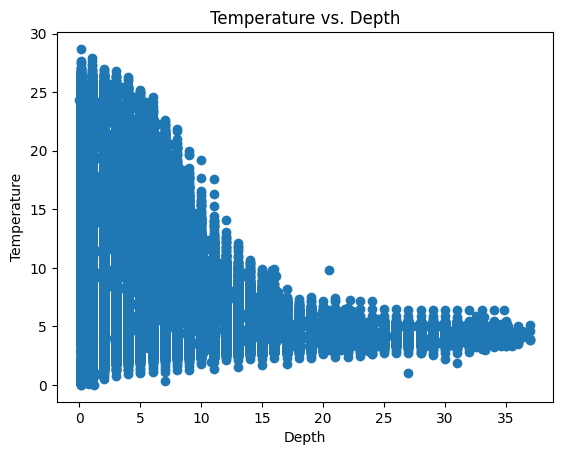

In [8]:
import matplotlib.pyplot as plt
temperature_depth = df.dropna(subset=['TEMPERATURE', 'DEPTH'])

plt.scatter(temperature_depth['DEPTH'], temperature_depth['TEMPERATURE'])
plt.xlabel('Depth')
plt.ylabel('Temperature')
plt.title('Temperature vs. Depth')
plt.show()


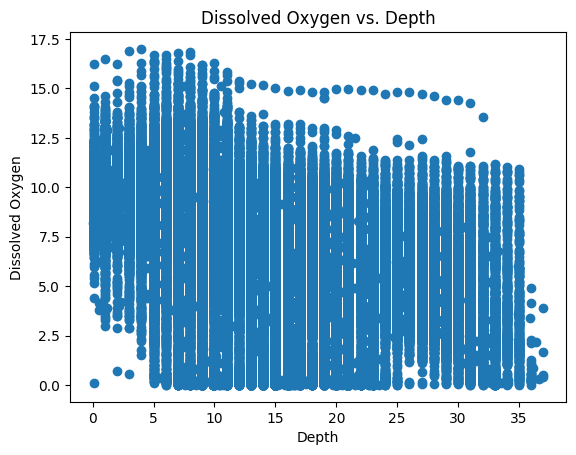

In [9]:
depth_dissolved_oxygen = df.dropna(subset=['DISSOLVED OXYGEN', 'DEPTH'])
plt.scatter(depth_dissolved_oxygen['DEPTH'], depth_dissolved_oxygen['DISSOLVED OXYGEN'])
plt.xlabel('Depth')
plt.ylabel('Dissolved Oxygen')
plt.title('Dissolved Oxygen vs. Depth')
plt.show()


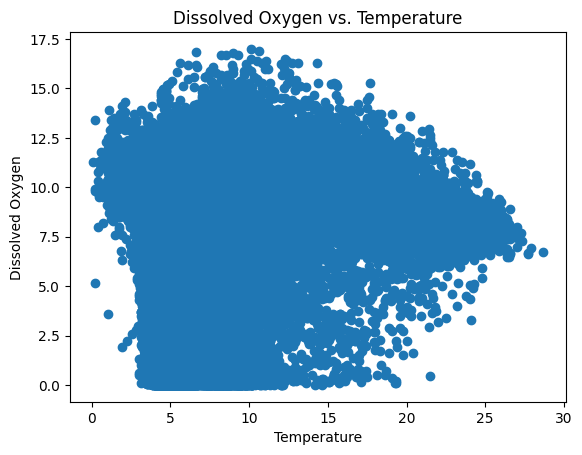

In [10]:
temperature_dissolved_oxygen = df.dropna(subset=['DISSOLVED OXYGEN', 'TEMPERATURE'])
plt.scatter(temperature_dissolved_oxygen['TEMPERATURE'], temperature_dissolved_oxygen['DISSOLVED OXYGEN'])
plt.xlabel('Temperature')
plt.ylabel('Dissolved Oxygen')
plt.title('Dissolved Oxygen vs. Temperature')
plt.show()


In [11]:
#correlation matrix that shows all the correlation between selected variables but in a table
correlation_matrix = df[['TEMPERATURE', 'DISSOLVED OXYGEN', 'DEPTH']].corr()

print(correlation_matrix)

                  TEMPERATURE  DISSOLVED OXYGEN     DEPTH
TEMPERATURE          1.000000          0.255888 -0.594653
DISSOLVED OXYGEN     0.255888          1.000000 -0.468555
DEPTH               -0.594653         -0.468555  1.000000


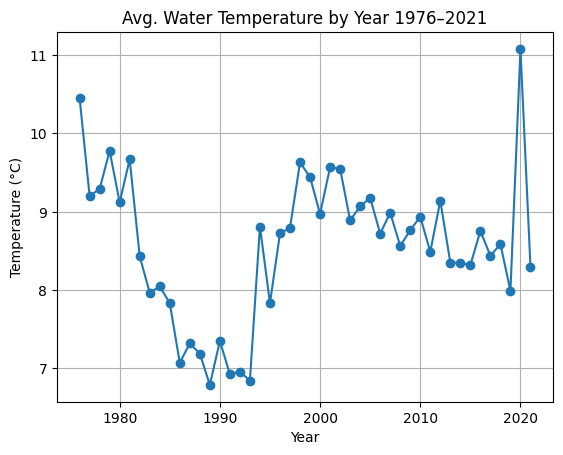

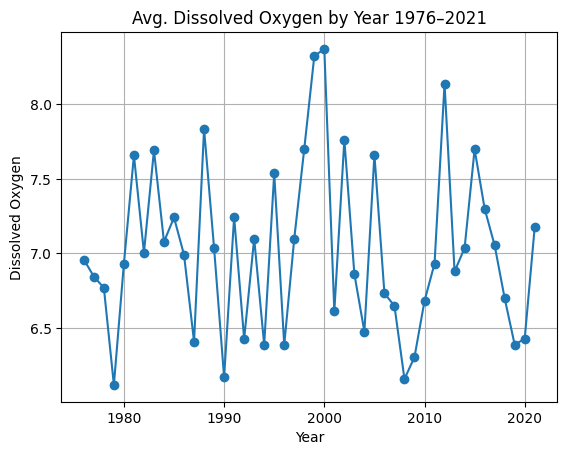

In [12]:
import matplotlib.pyplot as plt

# annual averages
avg_yearly_trends = df.groupby('YEAR')[['TEMPERATURE', 'DISSOLVED OXYGEN']].mean()

plt.plot(avg_yearly_trends.index, avg_yearly_trends['TEMPERATURE'], marker='o')
plt.title('Avg. Water Temperature by Year 1976–2021')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.grid(True)
plt.show()

plt.plot(avg_yearly_trends.index, avg_yearly_trends['DISSOLVED OXYGEN'], marker='o')
plt.title('Avg. Dissolved Oxygen by Year 1976–2021')
plt.xlabel('Year')
plt.ylabel('Dissolved Oxygen')
plt.grid(True)
plt.show()

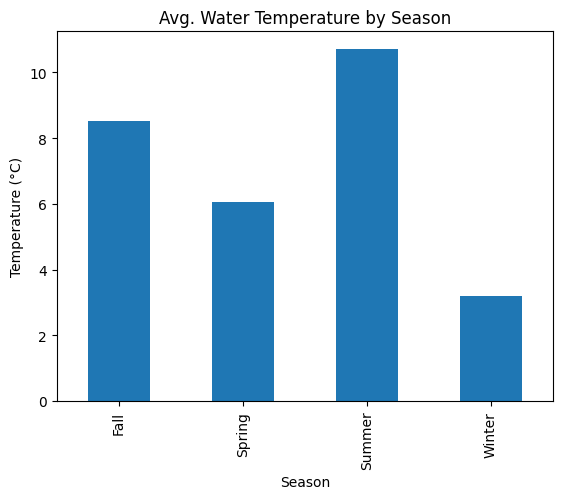

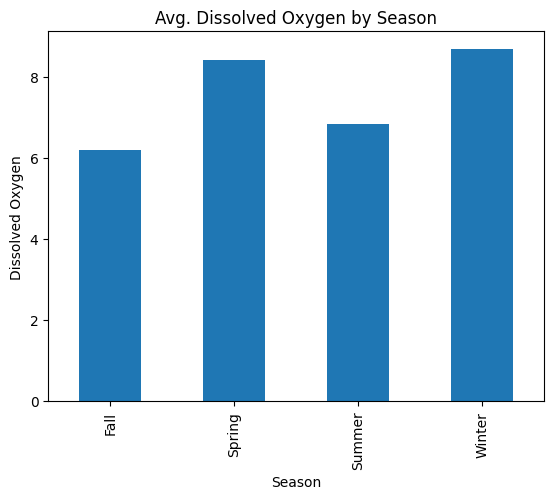

In [13]:
# avg analysis by season
avg_seasonal_trends = df.groupby('SEASON')[['TEMPERATURE', 'DISSOLVED OXYGEN']].mean()

avg_seasonal_trends['TEMPERATURE'].plot(kind='bar')
plt.title('Avg. Water Temperature by Season')
plt.xlabel('Season')
plt.ylabel('Temperature (°C)')
plt.show()

avg_seasonal_trends['DISSOLVED OXYGEN'].plot(kind='bar')
plt.title('Avg. Dissolved Oxygen by Season')
plt.xlabel('Season')
plt.ylabel('Dissolved Oxygen')
plt.show()

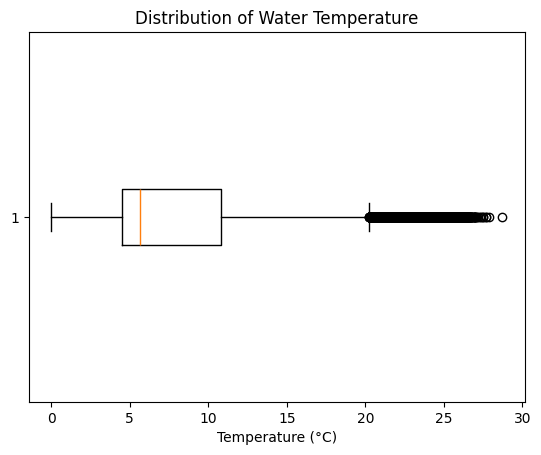

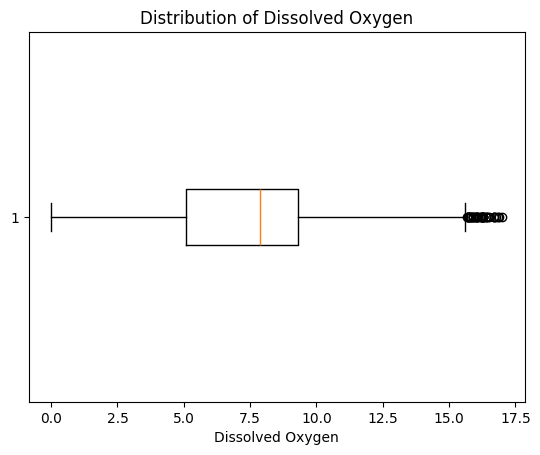

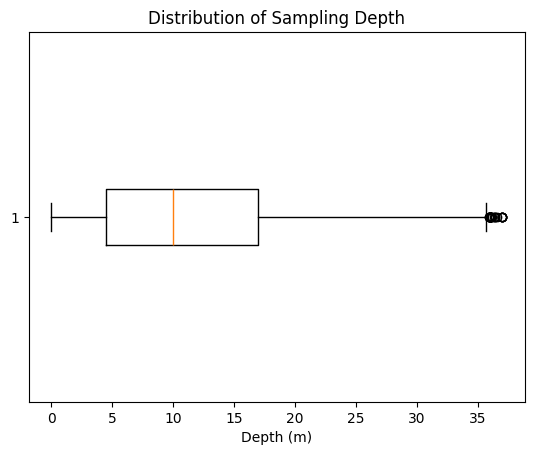

In [14]:
#boxplot to find outliers


plt.boxplot(df['TEMPERATURE'].dropna(), vert=False)
plt.xlabel('Temperature (°C)')
plt.title('Distribution of Water Temperature')
plt.show()

plt.boxplot(df['DISSOLVED OXYGEN'].dropna(), vert=False)
plt.xlabel('Dissolved Oxygen')
plt.title('Distribution of Dissolved Oxygen')
plt.show()

plt.boxplot(df['DEPTH'].dropna(), vert=False)
plt.xlabel('Depth (m)')
plt.title('Distribution of Sampling Depth')
plt.show()

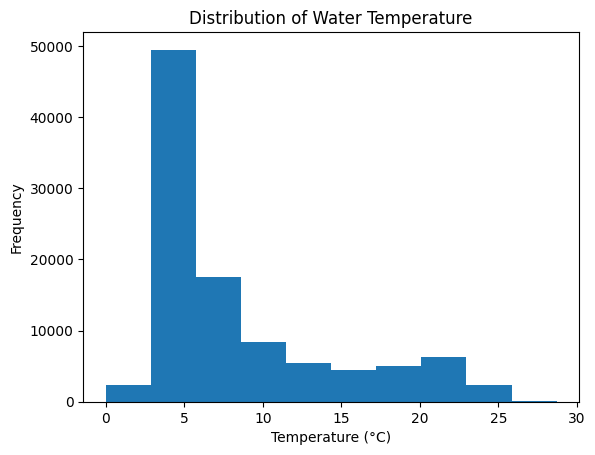

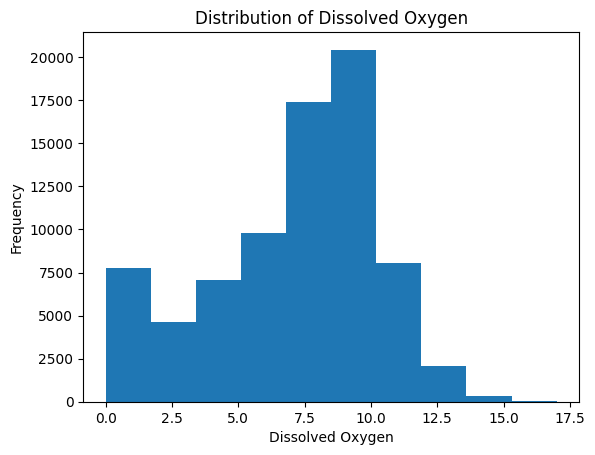

In [15]:
plt.hist(df['TEMPERATURE'].dropna())
plt.xlabel('Temperature (°C)')
plt.ylabel('Frequency')
plt.title('Distribution of Water Temperature')
plt.show()

plt.hist(df['DISSOLVED OXYGEN'].dropna())
plt.xlabel('Dissolved Oxygen')
plt.ylabel('Frequency')
plt.title('Distribution of Dissolved Oxygen')
plt.show()

In [16]:
print(df['LAKE'].unique())
print(df['SEASON'].unique())

['BLUE CHALK LAKE' 'CHUB LAKE' 'CROSSON LAKE' 'DICKIE LAKE' 'HARP LAKE'
 'HENEY LAKE' 'PLASTIC LAKE' 'RED CHALK LAKE - EAST'
 'RED CHALK LAKE - MAIN']
['Winter' 'Spring' 'Summer' 'Fall']


In [17]:
# removes the mssing observations for training/testing purposes
model_df = df[
    ['DISSOLVED OXYGEN', 'TEMPERATURE', 'DEPTH', 'YEAR', 'LAKE', 'SEASON']
].dropna()

print("Original rows:", len(df))
print("Rows available for modeling:", len(model_df))
print("Rows removed:", len(df) - len(model_df))

Original rows: 104319
Rows available for modeling: 76023
Rows removed: 28296


In [18]:
print(model_df['YEAR'].value_counts().sort_index())

YEAR
1976     209
1977    1977
1978    2002
1979    2267
1980    2244
1981    2445
1982    1446
1983    2390
1984    2289
1985    1989
1986    1837
1987    2046
1988    1986
1989    1784
1990    1814
1991    1810
1992    1275
1993    1116
1994     774
1995     911
1996     779
1997     760
1998    1550
1999    1729
2000    1793
2001    1565
2002    1704
2003    1860
2004    1890
2005    1778
2006    1785
2007    1843
2008    1765
2009    1915
2010    1989
2011    1835
2012    2042
2013    1741
2014    1753
2015    1613
2016    1711
2017    1816
2018    1465
2019    1408
2020     202
2021    1121
Name: count, dtype: int64


In [19]:
# years before 2011 are for training and years after 2012 are for testing
training_df = model_df[model_df['YEAR'] <= 2011].copy()
testing_df = model_df[model_df['YEAR'] >= 2012].copy()
print("Training rows:", len(training_df))
print("Testing rows:", len(testing_df))

Training rows: 61151
Testing rows: 14872


In [20]:
# second training set before and after 2006
training_df_v2 = model_df[model_df["YEAR"] <= 2006]
testing_df_v2 = model_df[(model_df["YEAR"] >= 2007) & (model_df["YEAR"] <= 2011)]

print("Training rows:", len(training_df_v2))
print("Testing rows:", len(testing_df_v2))

Training rows: 51804
Testing rows: 9347


In [21]:
X_train = training_df[['TEMPERATURE', 'DEPTH', 'YEAR', 'LAKE', 'SEASON']]
y_train = training_df['DISSOLVED OXYGEN']

X_test = testing_df[['TEMPERATURE', 'DEPTH', 'YEAR', 'LAKE', 'SEASON']]
y_test = testing_df['DISSOLVED OXYGEN']

print("Training predictors:", X_train.shape)
print("Training target:", y_train.shape)
print("Testing predictors:", X_test.shape)
print("Testing target:", y_test.shape)

Training predictors: (61151, 5)
Training target: (61151,)
Testing predictors: (14872, 5)
Testing target: (14872,)


In [22]:
# one hot encoding, converting lake and season variables into numerical columns
X_train_encoded = pd.get_dummies(X_train, columns=['LAKE', 'SEASON'], drop_first=True)

X_test_encoded = pd.get_dummies(X_test, columns=['LAKE', 'SEASON'], drop_first=True)

# aligning testing with training columns
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

print(X_train_encoded.columns.tolist())
print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

['TEMPERATURE', 'DEPTH', 'YEAR', 'LAKE_CHUB LAKE', 'LAKE_CROSSON LAKE', 'LAKE_DICKIE LAKE', 'LAKE_HARP LAKE', 'LAKE_HENEY LAKE', 'LAKE_PLASTIC LAKE', 'LAKE_RED CHALK LAKE - EAST', 'LAKE_RED CHALK LAKE - MAIN', 'SEASON_Spring', 'SEASON_Summer', 'SEASON_Winter']
Training shape: (61151, 14)
Testing shape: (14872, 14)


In [23]:
X_train_v2 = training_df_v2[["TEMPERATURE", "DEPTH", "YEAR", "LAKE", "SEASON"]]
y_train_v2 = training_df_v2["DISSOLVED OXYGEN"]

X_test_v2 = testing_df_v2[["TEMPERATURE", "DEPTH", "YEAR", "LAKE", "SEASON"]]
y_test_v2 = testing_df_v2["DISSOLVED OXYGEN"]


In [24]:
X_train_encoded_v2 = pd.get_dummies(X_train_v2, columns=["LAKE", "SEASON"], drop_first=True)
X_test_encoded_v2 = pd.get_dummies(X_test_v2, columns=["LAKE", "SEASON"], drop_first=True)

X_test_encoded_v2 = X_test_encoded_v2.reindex(columns=X_train_encoded_v2.columns, fill_value=0)

In [25]:
baseline_prediction = y_train.mean()

baseline_predictions = [baseline_prediction] * len(y_test)

print("Baseline prediction:", baseline_prediction)

Baseline prediction: 7.030662507563245


In [26]:
baseline_prediction_v2 = y_train_v2.mean()
baseline_predictions_v2 = [baseline_prediction_v2] * len(y_test_v2)

print("Baseline prediction:", baseline_prediction_v2)

Baseline prediction: 7.117758860319666


In [45]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
#function for MAE,RMSE, and R²
def evaluate_model(actual_values, predictions, model_name):
    mae = mean_absolute_error(actual_values, predictions)
    rmse = np.sqrt(mean_squared_error(actual_values, predictions))
    r2 = r2_score(actual_values, predictions)

    print(model_name, "MAE:", mae)
    print(model_name, "RMSE:", rmse)
    print(model_name, "R²:", r2)

In [46]:
#testing for baseline
evaluate_model(y_test, baseline_predictions, "Baseline")

Baseline MAE: 2.5972957184019094
Baseline RMSE: 3.210536133864065
Baseline R²: -0.0022070080796878777


In [47]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train_encoded, y_train)

linear_predictions = linear_model.predict(X_test_encoded)

#testing for linear regression model
evaluate_model(y_test, linear_predictions, "Linear Regression")

Linear Regression MAE: 1.9460843511113795
Linear Regression RMSE: 2.4697836603053442
Linear Regression R²: 0.40691063422545815


In [48]:
coefficients = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Coefficient": linear_model.coef_
})

coefficients.sort_values("Coefficient")

,Feature,Coefficient
9,LAKE_RED CHALK LAKE - EAST,-3.231803
5,LAKE_DICKIE LAKE,-2.495707
7,LAKE_HENEY LAKE,-1.549373
3,LAKE_CHUB LAKE,-1.454576
4,LAKE_CROSSON LAKE,-1.130457
8,LAKE_PLASTIC LAKE,-0.604545
1,DEPTH,-0.230670
2,YEAR,0.007825
0,TEMPERATURE,0.019643
12,SEASON_Summer,0.609100


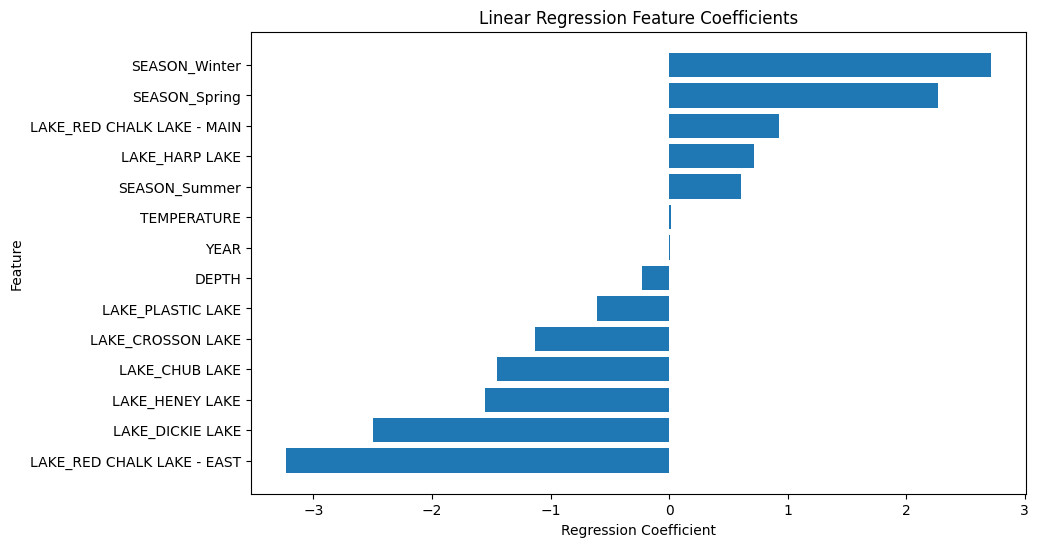

In [49]:
coefficients_sorted = coefficients.sort_values("Coefficient")

plt.figure(figsize=(10, 6))
plt.barh(coefficients_sorted["Feature"], coefficients_sorted["Coefficient"])
plt.xlabel("Regression Coefficient")
plt.ylabel("Feature")
plt.title("Linear Regression Feature Coefficients")
plt.show()

In [30]:
linear_model_v2 = LinearRegression()

linear_model_v2.fit(X_train_encoded_v2, y_train_v2)

linear_predictions_v2 = linear_model_v2.predict(X_test_encoded_v2)


In [31]:
#v2 metrics
evaluate_model(y_test_v2, baseline_predictions_v2, "Baseline v2")
evaluate_model(y_test_v2, linear_predictions_v2, "Linear Regression v2")

Baseline v2 MAE: 2.6282139249637906
Baseline v2 RMSE: 3.3258003128475027
Baseline v2 R²: -0.0302419269240497
Linear Regression v2 MAE: 2.013250059132359
Linear Regression v2 RMSE: 2.550156955328278
Linear Regression v2 R²: 0.39426774230955886


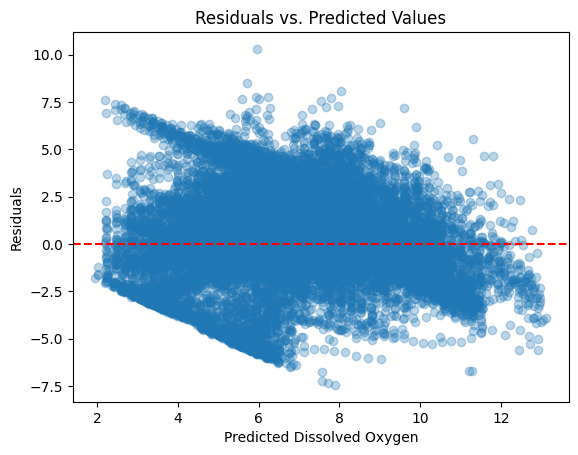

In [32]:
# Checking for residual plot patterns(test-prediction)
residuals = y_test - linear_predictions

plt.scatter(linear_predictions, residuals, alpha=0.3)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Dissolved Oxygen')
plt.ylabel('Residuals')
plt.title('Residuals vs. Predicted Values')

plt.show()

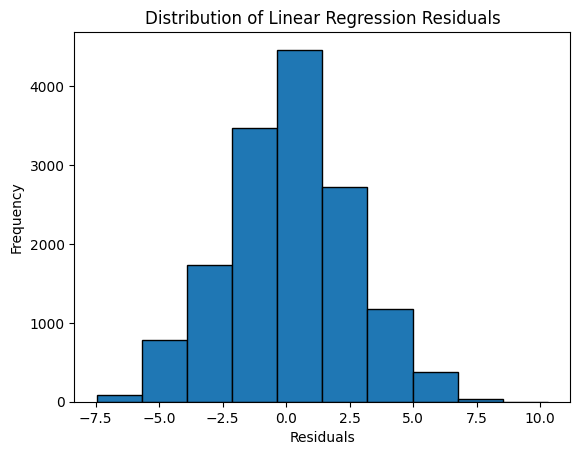

In [33]:
#Checking distribution of residuals

plt.hist(residuals, edgecolor='black')

plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Distribution of Linear Regression Residuals')

plt.show()

In [34]:
#non-parametric test
annual_do = df.groupby('YEAR')['DISSOLVED OXYGEN'].mean()

annual_do

,DISSOLVED OXYGEN
YEAR,
1976,6.959098
1977,6.845157
1978,6.769500
1979,6.118317
1980,6.931717
1981,7.657490
1982,7.005151
1983,7.691496
1984,7.078000


In [35]:
from scipy.stats import kendalltau

kendall_result = kendalltau(annual_do.index, annual_do.values)

print("Kendall:", kendall_result.statistic)
print("P-value:", kendall_result.pvalue)

Kendall: 0.004830917874396136
P-value: 0.9622416434573877


In [36]:
annual_temp = df.groupby('YEAR')['TEMPERATURE'].mean()

annual_temp

,TEMPERATURE
YEAR,
1976,10.455009
1977,9.204302
1978,9.289628
1979,9.778696
1980,9.119619
1981,9.671463
1982,8.431842
1983,7.966518
1984,8.049386


In [37]:
kendall_result_temp = kendalltau(annual_temp.index, annual_temp.values)

print("Kendall:", kendall_result_temp.statistic)
print("P-value:", kendall_result_temp.pvalue)

Kendall: -0.045410628019323676
P-value: 0.6563174885033158


In [38]:
seasonal_do = df.groupby(['YEAR', 'SEASON'])['DISSOLVED OXYGEN'].mean()

seasonal_do

YEAR  SEASON
1976  Fall      7.102176
      Spring    8.803571
      Summer    6.432613
      Winter    9.827941
1977  Fall      6.358260
                  ...   
2019  Summer    6.044068
2020  Summer    6.428564
2021  Fall      5.860810
      Spring    9.123642
      Summer    6.964722
Name: DISSOLVED OXYGEN, Length: 159, dtype: float64

In [39]:
seasonal_temp = df.groupby(['YEAR', 'SEASON'])['TEMPERATURE'].mean()

for season in df['SEASON'].unique():
    season_data = seasonal_temp.xs(season, level='SEASON')

    result = kendalltau(season_data.index, season_data.values)

    print(season)
    print("Kendall Tau:", result.statistic)
    print("P-value:", result.pvalue)
    print()

Winter
Kendall Tau: 0.4545454545454546
P-value: 0.001983031852676538

Spring
Kendall Tau: 0.11717171717171716
P-value: 0.2564804616392822

Summer
Kendall Tau: -0.5072463768115942
P-value: 6.668418520415959e-07

Fall
Kendall Tau: -0.3171717171717171
P-value: 0.0021288031240870716



In [40]:
for season in df['SEASON'].unique():
    season_data = seasonal_do.xs(season, level='SEASON')

    result = kendalltau(season_data.index, season_data.values)

    print(season)
    print("Kendall Tau:", result.statistic)
    print("P-value:", result.pvalue)
    print()

Winter
Kendall Tau: 0.1225296442687747
P-value: 0.43249287041044504

Spring
Kendall Tau: 0.3191919191919192
P-value: 0.001993405530846309

Summer
Kendall Tau: 0.10531400966183575
P-value: 0.302058744412545

Fall
Kendall Tau: -0.0020202020202020198
P-value: 0.9843906720046482



In [41]:
import time

start = time.time()
baseline_value = y_train.mean()
baseline_time = time.time() - start

linear_model.fit(X_train_encoded, y_train)
linear_time = time.time() - start

print("Baseline:", baseline_time, "secs")
print("Linear Regression:", linear_time, "secs")

Baseline: 0.0013873577117919922 secs
Linear Regression: 0.05800127983093262 secs


In [42]:
#Wilcoxon signed-rank test for Model A
#average errors across models absolute value
baseline_errors = np.abs(y_test - baseline_predictions)
linear_errors = np.abs(y_test - linear_predictions)

from scipy.stats import wilcoxon

statistic, p_value = wilcoxon(baseline_errors, linear_errors)

print("Wilcoxon statistic:", statistic)
print("P-value:", p_value)

Wilcoxon statistic: 32099617.0
P-value: 0.0


In [43]:
# Wilcoxon signed-rank test for Model B
baseline_errors_v2 = np.abs(y_test_v2 - baseline_predictions_v2)
linear_errors_v2 = np.abs(y_test_v2 - linear_predictions_v2)

statistic_v2, p_value_v2 = wilcoxon(baseline_errors_v2, linear_errors_v2)

print("Wilcoxon statistic:", statistic_v2)
print("P-value:", p_value_v2)

Wilcoxon statistic: 12816974.5
P-value: 2.4371104556892274e-262
